In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option('display.max_columns', None)


In [2]:
df = pd.read_csv("../data/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary:")
print(df.describe())

Shape: (1338, 7)

Columns:
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

Data types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1

Summary:
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


### EDA Observation
The dataset contains demographic and health-related variables along with the continuous target `charges`. Missing values and duplicate records are checked before modelling.

In [4]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1337, 7)


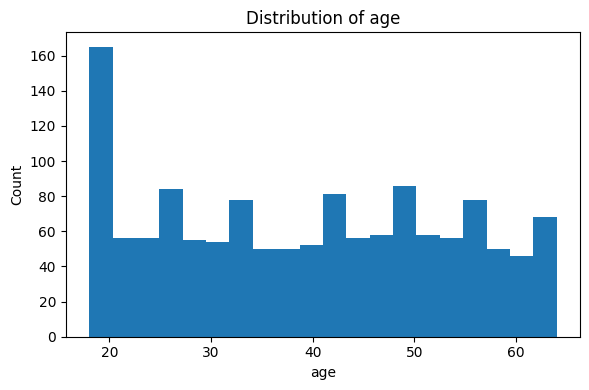

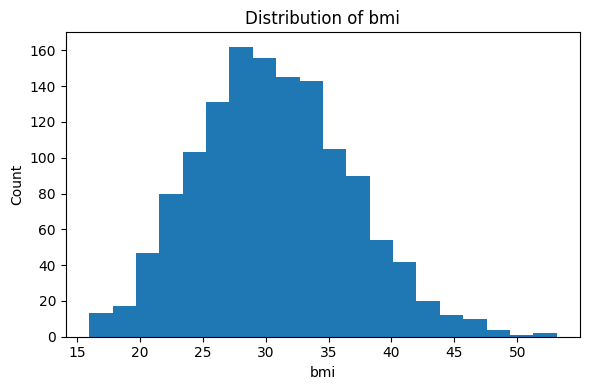

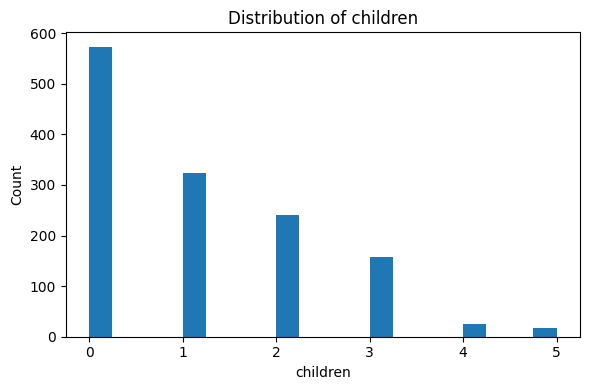

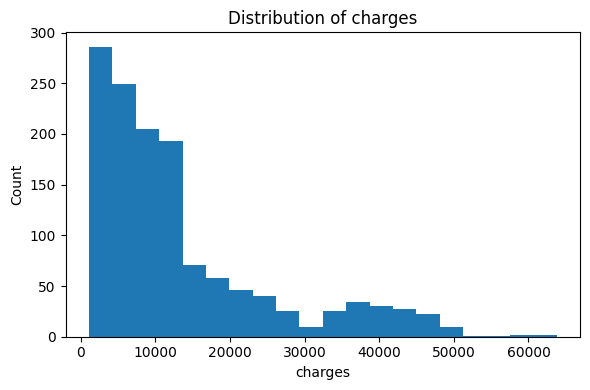

In [5]:
numeric_cols = ["age", "bmi", "children", "charges"]

for col in numeric_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=20)
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

### Distribution Observation
The numerical variables have different ranges. The `charges` variable is right-skewed, with some individuals having much higher medical expenses than the majority.

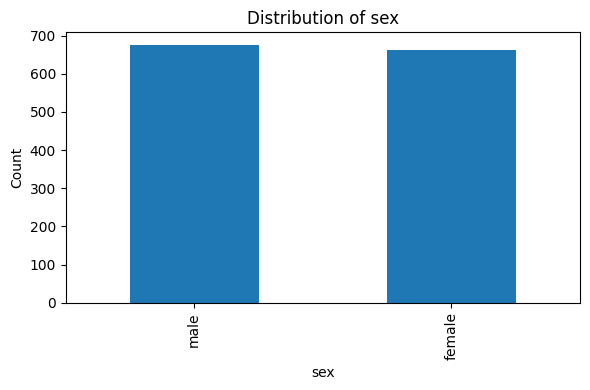

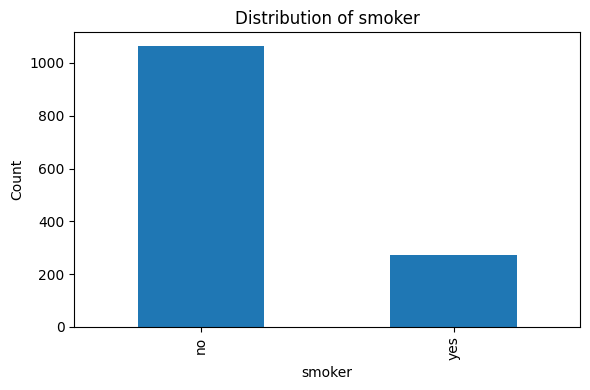

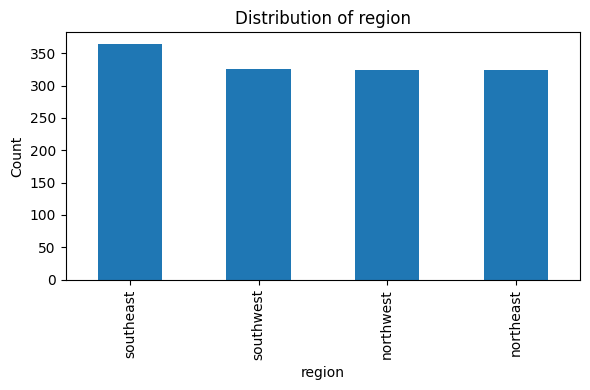

In [6]:
categorical_cols = ["sex", "smoker", "region"]

for col in categorical_cols:
    plt.figure(figsize=(6,4))
    df[col].value_counts().plot(kind="bar")
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

### Categorical Observation
The categorical plots show how the observations are distributed across sex, smoking status and residential region. Smoking status is especially useful for explaining differences in medical charges.

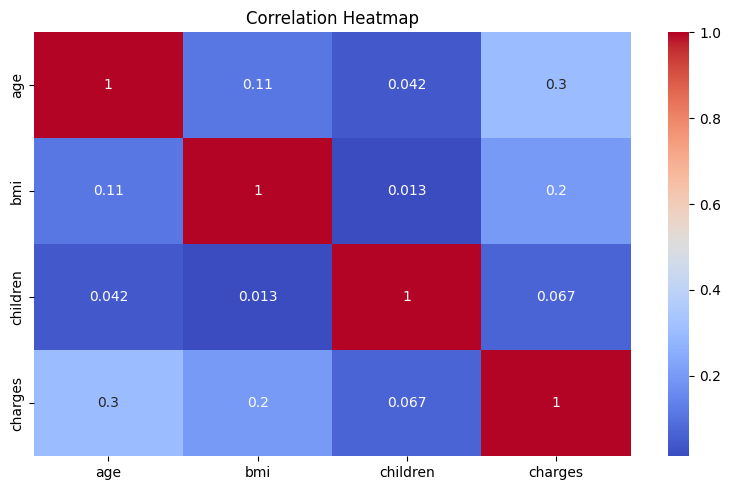

In [7]:
plt.figure(figsize=(8,5))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Correlation Observation
The heatmap helps identify relationships between numerical variables. The target `charges` has a noticeable relationship with some health and demographic variables, while several predictors have weaker direct correlations.

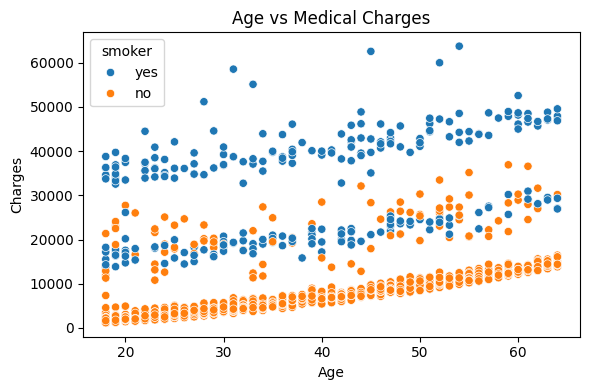

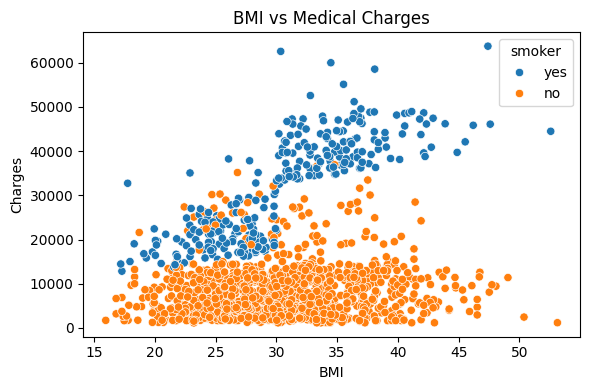

In [8]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")
plt.title("Age vs Medical Charges")
plt.xlabel("Age")
plt.ylabel("Charges")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,4))
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker")
plt.title("BMI vs Medical Charges")
plt.xlabel("BMI")
plt.ylabel("Charges")
plt.tight_layout()
plt.show()

### Scatter Plot Observation
Medical charges generally increase with age. BMI also shows a relationship with charges, and the smoker groups show clear differences in the level of medical expenses.

In [9]:
# Outlier check using IQR
outlier_table = []
for col in ["age", "bmi", "children"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_table.append([col, lower, upper, count])

outlier_table = pd.DataFrame(outlier_table, columns=["Feature","Lower Limit","Upper Limit","Outliers"])
outlier_table

,Feature,Lower Limit,Upper Limit,Outliers
0,age,-9.000,87.000,0
1,bmi,13.675,47.315,9
2,children,-3.000,5.000,0


### Outlier Treatment
Outliers in predictor variables are checked using the IQR method. Instead of deleting valid medical observations, extreme predictor values are capped at the IQR limits. The target `charges` is not capped because high medical costs can be meaningful observations.

In [10]:
for col in ["age", "bmi", "children"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df[col] = df[col].clip(lower, upper)

df["age_bmi"] = df["age"] * df["bmi"]
df.head()

,age,sex,bmi,children,smoker,region,charges,age_bmi
0,19,female,27.900,0,yes,southwest,16884.92400,530.100
1,18,male,33.770,1,no,southeast,1725.55230,607.860
2,28,male,33.000,3,no,southeast,4449.46200,924.000
3,33,male,22.705,0,no,northwest,21984.47061,749.265
4,32,male,28.880,0,no,northwest,3866.85520,924.160


### Feature Engineering Observation
The new `age_bmi` feature represents the interaction between age and BMI. It may help the models capture a combined effect that is not represented by age and BMI separately.

In [11]:
X = df.drop("charges", axis=1)
y = df["charges"]

X = pd.get_dummies(X, columns=["sex", "smoker", "region"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1069, 9)
Testing data: (268, 9)


### Preprocessing
Categorical variables are converted into numerical dummy variables. The data is split into 80% training and 20% testing data. StandardScaler is fitted only on the training data and then used for the test data.

# Regression Models

The following ten algorithms are required for Review 1. All models use the same train/test split.

In [12]:
results = []

### Linear Regression

In [13]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

results.append(["Linear Regression", r2, rmse, mae])
print("R2:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2: 0.8070379156399762
RMSE: 5954.658103633203
MAE: 4181.4391209675705


### Ridge Regression

In [14]:
model = Ridge(alpha=1.0)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

results.append(["Ridge Regression", r2, rmse, mae])
print("R2:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2: 0.8068816657998082
RMSE: 5957.068489349512
MAE: 4184.533195441968


### Lasso Regression

In [15]:
model = Lasso(alpha=0.1, max_iter=10000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

results.append(["Lasso Regression", r2, rmse, mae])
print("R2:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2: 0.8070362268890139
RMSE: 5954.684160339198
MAE: 4181.4688297931825


### ElasticNet Regression

In [16]:
model = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

results.append(["ElasticNet Regression", r2, rmse, mae])
print("R2:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2: 0.7969484187070918
RMSE: 6108.351608716229
MAE: 4337.254186306165


### Polynomial Regression

In [17]:
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)
model = LinearRegression()
model.fit(X_train_poly, y_train)
y_pred = model.predict(X_test_poly)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

results.append(["Polynomial Regression", r2, rmse, mae])
print("R2:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2: 0.881214650121401
RMSE: 4671.994045312583
MAE: 2931.541949337589


### Decision Tree Regressor

In [18]:
model = DecisionTreeRegressor(max_depth=5, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

results.append(["Decision Tree Regressor", r2, rmse, mae])
print("R2:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2: 0.8961182642319298
RMSE: 4369.084445338413
MAE: 2640.292880039281


### Random Forest Regressor

In [19]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

results.append(["Random Forest Regressor", r2, rmse, mae])
print("R2:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2: 0.8807285596825332
RMSE: 4681.543594291375
MAE: 2638.1425434152984


### Gradient Boosting Regressor

In [20]:
model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

results.append(["Gradient Boosting Regressor", r2, rmse, mae])
print("R2:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2: 0.8988615864307383
RMSE: 4311.008791553138
MAE: 2514.0844212671195


### Support Vector Regressor

In [21]:
model = SVR(kernel='rbf', C=100)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

results.append(["Support Vector Regressor", r2, rmse, mae])
print("R2:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2: 0.1344673104302534
RMSE: 12611.379002085512
MAE: 6626.887166262417


### KNN Regressor

In [22]:
model = KNeighborsRegressor(n_neighbors=5)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

results.append(["KNN Regressor", r2, rmse, mae])
print("R2:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2: 0.8353300395560889
RMSE: 5500.827555648026
MAE: 3410.3773558694024


### Model Comparison

In [23]:
results_df = pd.DataFrame(results, columns=["Model","R2","RMSE","MAE"])
results_df = results_df.sort_values("R2", ascending=False).reset_index(drop=True)
results_df

,Model,R2,RMSE,MAE
0,Gradient Boosting Regressor,0.898862,4311.008792,2514.084421
1,Decision Tree Regressor,0.896118,4369.084445,2640.292880
2,Polynomial Regression,0.881215,4671.994045,2931.541949
3,Random Forest Regressor,0.880729,4681.543594,2638.142543
4,KNN Regressor,0.835330,5500.827556,3410.377356
5,Linear Regression,0.807038,5954.658104,4181.439121
6,Lasso Regression,0.807036,5954.684160,4181.468830
7,Ridge Regression,0.806882,5957.068489,4184.533195
8,ElasticNet Regression,0.796948,6108.351609,4337.254186
9,Support Vector Regressor,0.134467,12611.379002,6626.887166


### Comparison Observation
The comparison table ranks all ten regression algorithms using the same test set. A higher R² and lower RMSE/MAE indicate better predictive performance.

## Hyperparameter Tuning

In [24]:
# Tune Random Forest
rf = RandomForestRegressor(random_state=42)

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 8]
}

grid_rf = GridSearchCV(rf, param_grid, cv=5, scoring="r2")
grid_rf.fit(X_train, y_train)

rf_best = grid_rf.best_estimator_
rf_pred = rf_best.predict(X_test)

print("Best Random Forest parameters:", grid_rf.best_params_)
print("Before tuning R2:", results_df[results_df["Model"]=="Random Forest Regressor"]["R2"].iloc[0])
print("After tuning R2:", r2_score(y_test, rf_pred))

Best Random Forest parameters: {'max_depth': 5, 'n_estimators': 100}
Before tuning R2: 0.8807285596825332
After tuning R2: 0.9016680962914471


In [25]:
# Tune Gradient Boosting
gb = GradientBoostingRegressor(random_state=42)

param_grid = {
    "n_estimators": [50, 100],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3]
}

grid_gb = GridSearchCV(gb, param_grid, cv=5, scoring="r2")
grid_gb.fit(X_train, y_train)

gb_best = grid_gb.best_estimator_
gb_pred = gb_best.predict(X_test)

print("Best Gradient Boosting parameters:", grid_gb.best_params_)
print("Before tuning R2:", results_df[results_df["Model"]=="Gradient Boosting Regressor"]["R2"].iloc[0])
print("After tuning R2:", r2_score(y_test, gb_pred))

Best Gradient Boosting parameters: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
Before tuning R2: 0.8988615864307383
After tuning R2: 0.9006152906063455


## 5-Fold Cross Validation for the Two Best Models

In [26]:
top_two = results_df.head(2)
top_two

,Model,R2,RMSE,MAE
0,Gradient Boosting Regressor,0.898862,4311.008792,2514.084421
1,Decision Tree Regressor,0.896118,4369.084445,2640.292880


In [27]:
# Cross-validation is performed on the two best models from the comparison table
cv_results = []

for name in top_two["Model"]:
    if name == "Linear Regression":
        m = LinearRegression()
        scores = cross_val_score(m, X_train_scaled, y_train, cv=5, scoring="r2")
    elif name == "Ridge Regression":
        m = Ridge(alpha=1.0)
        scores = cross_val_score(m, X_train_scaled, y_train, cv=5, scoring="r2")
    elif name == "Lasso Regression":
        m = Lasso(alpha=0.1, max_iter=10000)
        scores = cross_val_score(m, X_train_scaled, y_train, cv=5, scoring="r2")
    elif name == "ElasticNet Regression":
        m = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
        scores = cross_val_score(m, X_train_scaled, y_train, cv=5, scoring="r2")
    elif name == "Polynomial Regression":
        m = LinearRegression()
        scores = cross_val_score(m, PolynomialFeatures(degree=2).fit_transform(X_train_scaled), y_train, cv=5, scoring="r2")
    elif name == "Decision Tree Regressor":
        m = DecisionTreeRegressor(max_depth=5, random_state=42)
        scores = cross_val_score(m, X_train, y_train, cv=5, scoring="r2")
    elif name == "Random Forest Regressor":
        m = RandomForestRegressor(n_estimators=100, random_state=42)
        scores = cross_val_score(m, X_train, y_train, cv=5, scoring="r2")
    elif name == "Gradient Boosting Regressor":
        m = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
        scores = cross_val_score(m, X_train, y_train, cv=5, scoring="r2")
    elif name == "Support Vector Regressor":
        m = SVR(kernel="rbf", C=100)
        scores = cross_val_score(m, X_train_scaled, y_train, cv=5, scoring="r2")
    else:
        m = KNeighborsRegressor(n_neighbors=5)
        scores = cross_val_score(m, X_train_scaled, y_train, cv=5, scoring="r2")
    cv_results.append([name, scores.mean(), scores.std()])

cv_df = pd.DataFrame(cv_results, columns=["Model","Mean CV R2","Std CV R2"])
cv_df

,Model,Mean CV R2,Std CV R2
0,Gradient Boosting Regressor,0.845550,0.020529
1,Decision Tree Regressor,0.827509,0.015807


## Best Model Visualizations

Best model based on test R2: Gradient Boosting Regressor


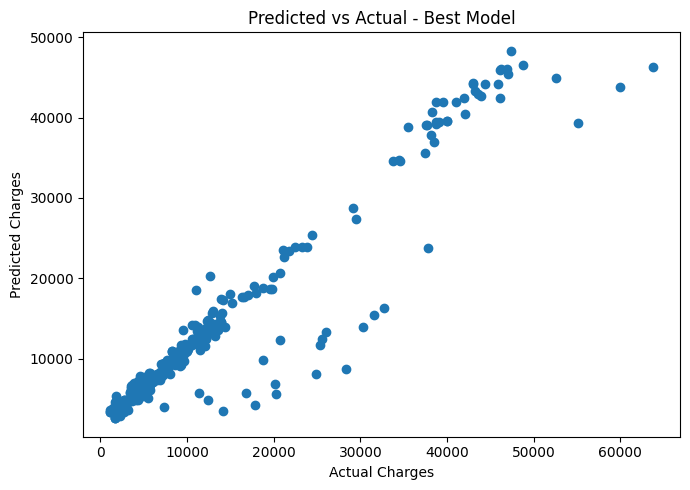

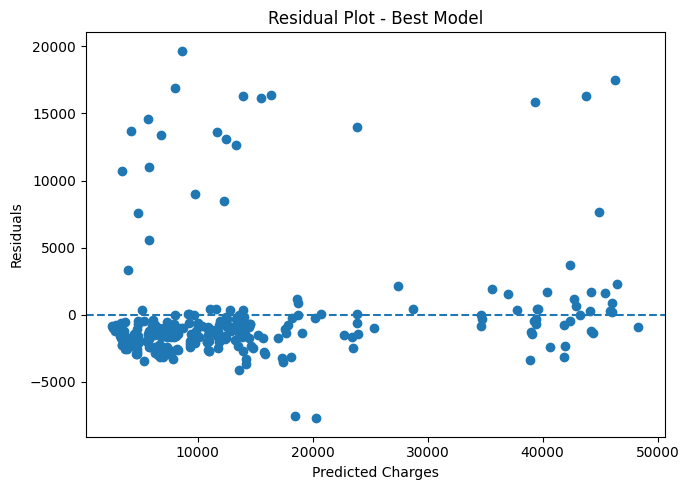

In [28]:
best_name = results_df.iloc[0]["Model"]
print("Best model based on test R2:", best_name)

if best_name == "Linear Regression":
    best_model = LinearRegression()
    best_model.fit(X_train_scaled, y_train)
    best_pred = best_model.predict(X_test_scaled)
elif best_name == "Ridge Regression":
    best_model = Ridge(alpha=1.0)
    best_model.fit(X_train_scaled, y_train)
    best_pred = best_model.predict(X_test_scaled)
elif best_name == "Lasso Regression":
    best_model = Lasso(alpha=0.1, max_iter=10000)
    best_model.fit(X_train_scaled, y_train)
    best_pred = best_model.predict(X_test_scaled)
elif best_name == "ElasticNet Regression":
    best_model = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
    best_model.fit(X_train_scaled, y_train)
    best_pred = best_model.predict(X_test_scaled)
elif best_name == "Polynomial Regression":
    poly = PolynomialFeatures(degree=2)
    X_train_poly = poly.fit_transform(X_train_scaled)
    X_test_poly = poly.transform(X_test_scaled)
    best_model = LinearRegression()
    best_model.fit(X_train_poly, y_train)
    best_pred = best_model.predict(X_test_poly)
elif best_name == "Decision Tree Regressor":
    best_model = DecisionTreeRegressor(max_depth=5, random_state=42)
    best_model.fit(X_train, y_train)
    best_pred = best_model.predict(X_test)
elif best_name == "Random Forest Regressor":
    best_model = RandomForestRegressor(n_estimators=100, random_state=42)
    best_model.fit(X_train, y_train)
    best_pred = best_model.predict(X_test)
elif best_name == "Gradient Boosting Regressor":
    best_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
    best_model.fit(X_train, y_train)
    best_pred = best_model.predict(X_test)
elif best_name == "Support Vector Regressor":
    best_model = SVR(kernel="rbf", C=100)
    best_model.fit(X_train_scaled, y_train)
    best_pred = best_model.predict(X_test_scaled)
else:
    best_model = KNeighborsRegressor(n_neighbors=5)
    best_model.fit(X_train_scaled, y_train)
    best_pred = best_model.predict(X_test_scaled)

plt.figure(figsize=(7,5))
plt.scatter(y_test, best_pred)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Predicted vs Actual - Best Model")
plt.tight_layout()
plt.show()

residuals = y_test - best_pred
plt.figure(figsize=(7,5))
plt.scatter(best_pred, residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.title("Residual Plot - Best Model")
plt.tight_layout()
plt.show()

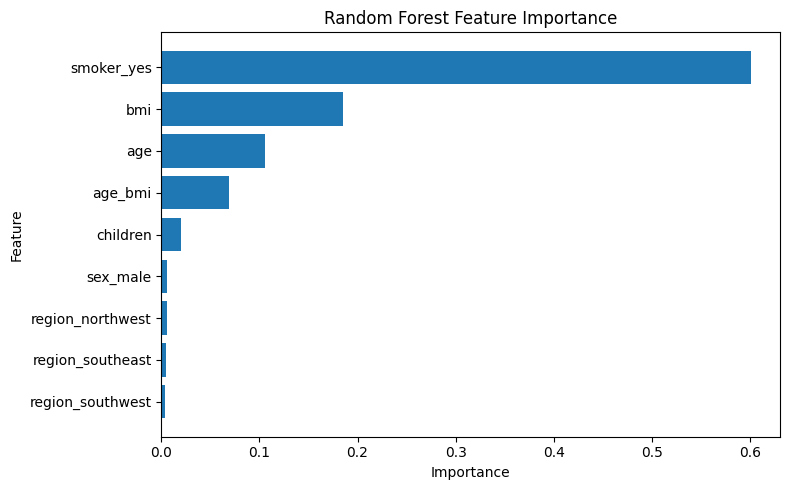

,Feature,Importance
5,smoker_yes,0.600777
1,bmi,0.184996
0,age,0.105597
3,age_bmi,0.068893
2,children,0.020310
4,sex_male,0.005328
6,region_northwest,0.005226
7,region_southeast,0.005164
8,region_southwest,0.003710


In [29]:
# Feature importance for Random Forest
rf_importance = RandomForestRegressor(n_estimators=100, random_state=42)
rf_importance.fit(X_train, y_train)

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_importance.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(8,5))
plt.barh(importance["Feature"], importance["Importance"])
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

importance

### Final Regression Conclusion
The ten regression models were compared using R², RMSE and MAE. Hyperparameter tuning was performed for Random Forest and Gradient Boosting, and 5-fold cross-validation was applied to the two best-performing models. The best model is selected based on the test-set comparison and its prediction behaviour is visualized using predicted-vs-actual and residual plots.

## Review 1 Regression Checklist
- 10 required regression algorithms
- Same held-out test set
- R², RMSE and MAE comparison
- GridSearchCV for at least two models
- Best parameters and improvement
- 5-fold CV for two best models
- Residual plot
- Predicted-vs-actual plot
- Tree feature importance